In [55]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.arima_process import arma_generate_sample

In [56]:
ar_coef = [1, -0.5]
ma_coef =[1,0.2]

In [57]:
sample = arma_generate_sample(ar=ar_coef, ma= ma_coef, nsample=1000)
sample = pd.DataFrame(sample, columns=['value'])

In [58]:
sample.index = pd.date_range(start='2022-01-01',periods = len(sample), freq='D')

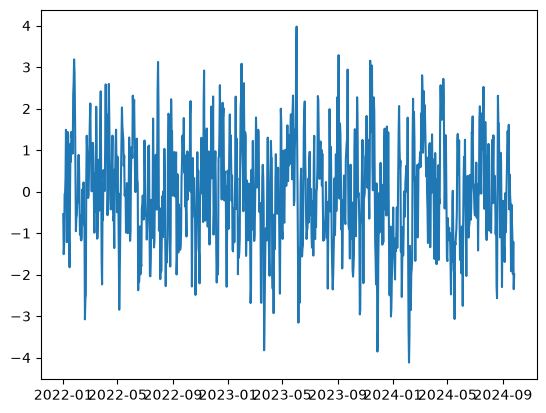

In [59]:
plt.plot(sample)
plt.show()

In [60]:
from statsmodels.tsa.arima.model import ARIMA

In [61]:
model = ARIMA(sample, order =(1,0,1))


In [62]:
results = model.fit()

In [63]:
results.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                               SARIMAX Results                                
==============================================================================
Dep. Variable:                  value   No. Observations:                 1000
Model:                 ARIMA(1, 0, 1)   Log Likelihood               -1394.045
Date:                Fri, 02 Oct 2026   AIC                           2796.089
Time:                        14:32:38   BIC                           2815.720
Sample:                    01-01-2022   HQIC                          2803.550
                         - 09-26-2024                                         
Covariance Type:                  opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.0220      0.076     -0.288      0.773      -0.172       0.128
ar.L1          0.5048      0.043     11.856      0.000       0.421       0.588
ma.L1          0.2247      0.047      4.748      0.000       0.132       0.317
sigma2         0.9509      0.043     22.071      0.000       0.866       1.035
===================================================================================
Ljung-Box (L1) (Q):                   0.01   Jarque-Bera (JB):                 0.73
Prob(Q):                              0.90   Prob(JB):                         0.70
Heteroskedasticity (H):               1.12   Skew:                            -0.06
Prob(H) (two-sided):                  0.31   Kurtosis:                         2.95
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""

In [64]:
results.params

const    -0.022013
ar.L1     0.504827
ma.L1     0.224710
sigma2    0.950887
dtype: float64

In [65]:
#arma model takes an exogenous variable as an argument.

In [86]:
forecast = results.get_prediction(start=900, end=1000, dynamic=False)

In [87]:
ci_values = forecast.conf_int()
pred_mean = forecast.predicted_mean

In [88]:
upper_lim = ci_values['upper value']
lower_lim = ci_values['lower value']

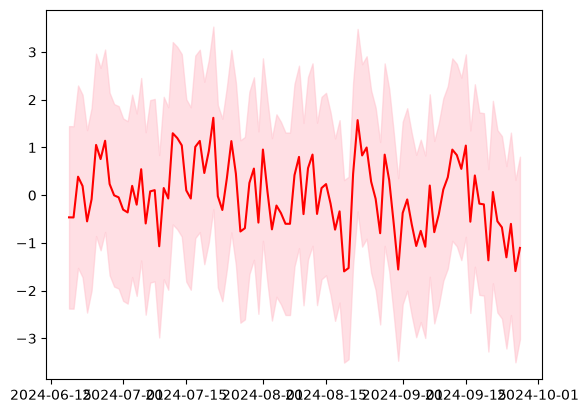

In [89]:
plt.plot(pred_mean.index, pred_mean.values, color='r')
plt.fill_between(lower_lim.index, lower_lim.values, upper_lim.values, color='pink', alpha=0.5)
plt.show()

In [90]:
forecast2 = results.get_forecast(steps=21)

In [91]:
forecast_mean = forecast2.predicted_mean
ci_values2 = forecast2.conf_int()

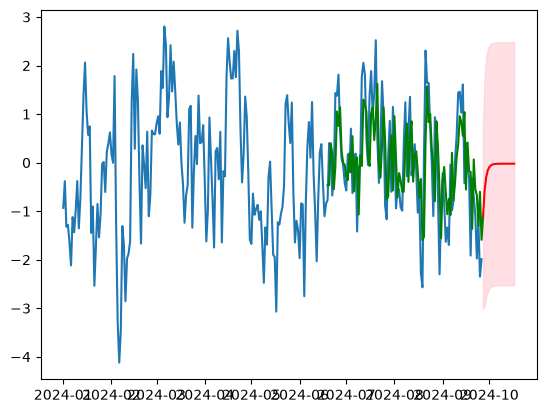

In [92]:
plt.plot(sample['2024':])
plt.plot(pred_mean.index, pred_mean.values, color='green')
plt.plot(forecast_mean, color='r')
plt.fill_between(ci_values2.index, ci_values2.iloc[:,0], ci_values2.iloc[:,1], color='pink', alpha=0.5)